General information

In [ ]:
# Time/year/month etc. use time_period as a parameter
# everything else, use filters as a parameter

Import libraries

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

Import class

In [15]:
import sys
sys.path.insert(0, '..')

from src.fetcher import SSBcsvFetcher

fetcher = SSBcsvFetcher()

Fetch DataFrame

In [17]:
#df = fetcher.fetch_clean_table('05810', filters={'Kjonn': '0'}, )
df = fetcher.fetch_clean_table('05810', time_period='*', filters={'Kjonn': '0'})
df.head()

# Only men, all age groups, all years
#df_men = fetcher.fetch_clean_table('05810', time_period='*', filters={'Kjonn': '1'})
#df.head()

INFO:src.api:Fetching dimensions for table 05810
INFO:src.api:Fetching pivot table 05810
INFO:src.api:URL: https://data.ssb.no/api/pxwebapi/v2/tables/05810/data?lang=no&outputformat=csv&outputformatparams=separatorsemicolon,usecodesandtexts&stub=Tid&heading=statistikkvariabel&valuecodes[Tid]=%2A&valuecodes[Kjonn]=0&valuecodes[Alder]=*&valuecodes[ContentsCode]=*
INFO:src.api:Successfully fetched 7 rows


,kjønn,alder,1845,1850,1855,1860,1865,1870,1875,1880,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Begge kjønn,Alle,1329616,1399733,1490786,1608653,1701756,1741162,1818853,1923283,...,5213985,5258317,5295619,5328212,5367580,5391369,5425270,5488984,5550203,5594340
1,Begge kjønn,0-6 år,226255,242884,272584,306920,316145,303456,309735,346190,...,435800,431811,426149,419224,412551,404800,401490,398145,393296,390630
2,Begge kjønn,7-15 år,247079,254731,273574,304236,330096,348192,353273,354710,...,562443,568214,574139,578380,580984,580047,579581,583568,585985,581299
3,Begge kjønn,16-44 år,566700,601413,630862,672773,701778,713355,740486,780710,...,2031560,2036980,2037328,2037852,2045028,2045163,2053674,2084456,2111765,2130051
4,Begge kjønn,45-66 år,226005,236925,243519,243870,266231,286125,320193,342913,...,1439486,1455310,1471644,1487062,1501597,1511702,1519562,1530972,1543676,1554724


Simple cleaning

In [18]:
# drop first row in df
df = df.iloc[1:]

# drop first column in df
df = df.iloc[:, 1:]

Create grouped horizontal barchart (age y axis) and their count with years 2020 to 2025 in x axis

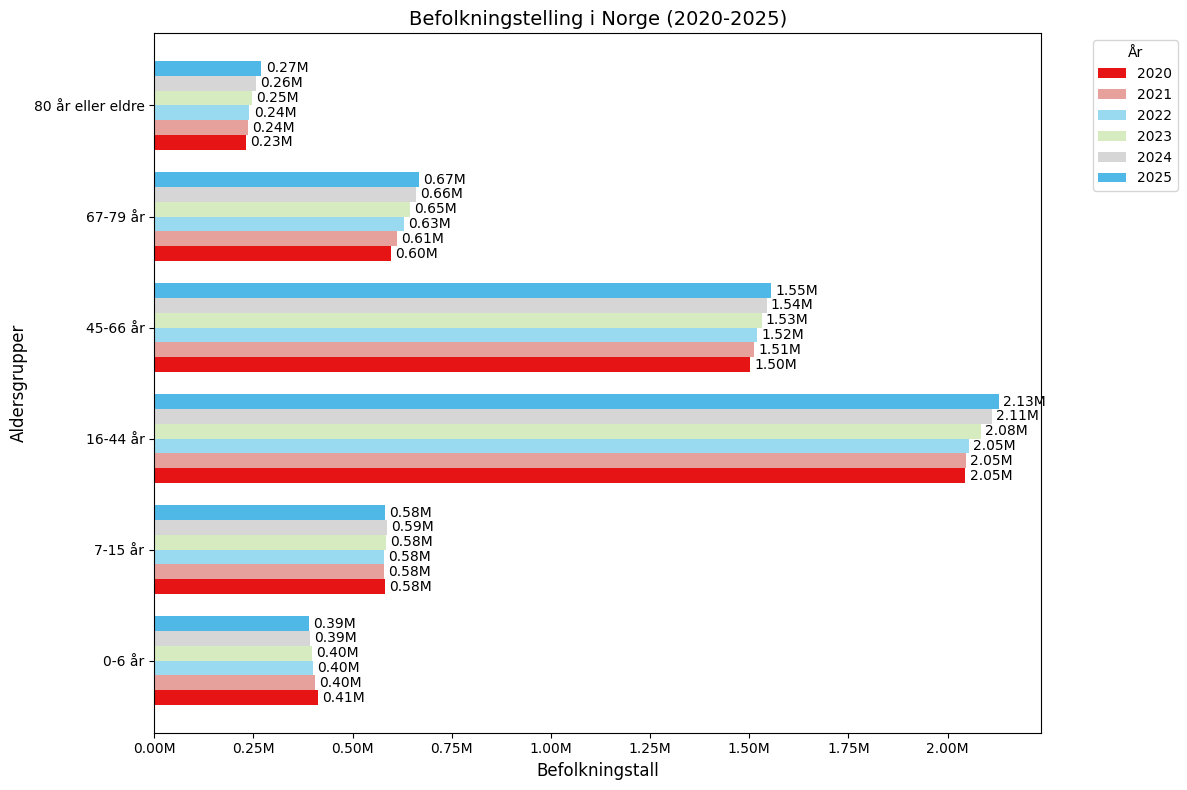

In [30]:
# Filter columns for years 2020-2025
year_columns = [col for col in df.columns if str(col).isdigit() and 2020 <= int(col) <= 2025]
df_filtered = df.set_index('alder')[year_columns].astype(float)

# Define colors
colors = ['#e61414', '#E7A19C', '#99daf0', '#d6ecc0', '#D6D6D6', '#50b8e7']  # Extra color at end

# Create grouped horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

df_filtered.plot(kind='barh', ax=ax, width=0.8, color=colors)

ax.set_xlabel('Befolkningstall', fontsize=12)
ax.set_ylabel('Aldersgrupper', fontsize=12)
ax.set_title('Befolkningstelling i Norge (2020-2025)', fontsize=14)
ax.legend(title='År', bbox_to_anchor=(1.05, 1), loc='upper left')

# Format x-axis to show millions
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1e6:.2f}M'))

# Add value labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt=lambda x: f'{x/1e6:.2f}M', padding=3)

plt.tight_layout()
plt.show()